# 06b - XAI du modèle de référence : SHAP sur le gradient boosting

Objectif : savoir sur quelles variables repose le gradient boosting de `02_baseline.ipynb`, et quelle part revient au pays. C'est le point de comparaison de `06_xai.ipynb`, qui pose la même question au LLM.

**Pour lancer :** sur un PC, sans GPU, après `pip install -r requirements.txt`. Seul `data/prompts/` est nécessaire. `data/game_ids.csv` (non versionné) permet en plus de calculer l'intervalle de confiance par joueur ; sans lui, il est calculé par partie.

**Protocole.**
- Le modèle est celui de `02_baseline.ipynb` : même encodage, mêmes hyperparamètres (ceux retenus sur val, sans refaire la recherche), entraînement sur train. La cellule s'arrête si la MAE sur le test ne redonne pas 369.
- Les explications portent sur les 427 parties du test hors leaderboard, comme dans `06_xai.ipynb`. Le modèle, lui, reste entraîné avec les parties de leaderboard, comme dans 02.
- Les 131 colonnes de l'encodage sont regroupées par variable d'origine : la contribution d'une variable est la somme de celles de ses colonnes.

**Pourquoi `feature_perturbation="tree_path_dependent"` ?** Le mode `interventional`, qui utilise un fond de parties, ne respecte pas l'additivité sur ce modèle avec shap 0.54 : la somme des contributions s'écarte de la prédiction, jusqu'à 90 points. Le mode retenu est exact, et le contrôle d'additivité de shap reste actif.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROMPTS_DIR = Path("data/prompts")
GAME_IDS_FILE = Path("data/game_ids.csv")  # correspondance locale, non versionnée : elle contient les pseudos
OUTPUT_DIR = Path("resultats_xai_baseline")
OUTPUT_DIR.mkdir(exist_ok=True)

ELO_FLOOR = 100
EXPECTED_MAE = 369  # 02_baseline.ipynb
BEST_PARAMS = {"learning_rate": 0.1, "max_depth": 3, "max_iter": 500, "loss": "absolute_error"}  # retenus sur val dans 02_baseline.ipynb
CATEGORICAL = ["country", "color", "opening_name", "eco", "result", "termination"]
NUMERIC = ["nb_moves", "nb_blunders", "nb_mistakes", "nb_inaccuracies", "acpl", "blunders_per_move"]
MIN_CATEGORY_GAMES = 10  # les modalités plus rares (1 827 ouvertures au total) sont regroupées
COUNTRY_ORDER = ["BR", "DE", "FR", "IN", "US"]
COUNTRY_NAMES = {"BR": "Brésil", "DE": "Allemagne", "FR": "France", "IN": "Inde", "US": "États-Unis"}
LABELS = {"country": "Pays", "color": "Couleur", "opening_name": "Ouverture", "eco": "Code ECO", "result": "Résultat", "termination": "Fin de partie", "nb_moves": "Nombre de coups",
          "nb_blunders": "Gaffes", "nb_mistakes": "Erreurs", "nb_inaccuracies": "Imprécisions", "acpl": "ACPL", "blunders_per_move": "Gaffes par coup"}
NB_BOOTSTRAP = 5000
SEED = 42

INK, INK_2, GRID, MUTED, ACCENT = "#0b0b0b", "#52514e", "#e4e3de", "#c9c8c2", "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (13.33, 7.5), "figure.dpi": 90, "savefig.dpi": 200, "figure.facecolor": "white",
    "font.size": 15, "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.axisbelow": True, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 1, "xtick.color": INK_2, "ytick.color": INK, "text.color": INK,
    "xtick.bottom": False, "ytick.left": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "legend.frameon": False,
})


def load_split(name):
    with open(PROMPTS_DIR / f"{name}.jsonl", encoding="utf-8") as file:
        return pd.DataFrame([json.loads(line) for line in file])


train, test = load_split("train"), load_split("test")
explained = test[test["source"] != "leaderboard"].reset_index(drop=True)
print(f"shap {shap.__version__} | train : {len(train)} parties | test : {len(test)} parties, dont {len(explained)} hors leaderboard")

shap 0.54.1 | train : 3332 parties | test : 437 parties, dont 427 hors leaderboard


## 1. Le modèle de `02_baseline.ipynb`

In [2]:
encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_CATEGORY_GAMES, sparse_output=False)
pipeline = make_pipeline(ColumnTransformer([("cat", encoder, CATEGORICAL), ("num", StandardScaler(), NUMERIC)]),
                         HistGradientBoostingRegressor(random_state=42, **BEST_PARAMS))
pipeline.fit(train[CATEGORICAL + NUMERIC], train["elo"])
preprocess, booster = pipeline[0], pipeline[1]

mae = mean_absolute_error(test["elo"], np.clip(pipeline.predict(test[CATEGORICAL + NUMERIC]), ELO_FLOOR, None))
if round(mae) != EXPECTED_MAE:
    raise ValueError(f"MAE de {mae:.1f} sur le test : ce n'est pas le modèle de 02_baseline.ipynb ({EXPECTED_MAE})")
print(f"MAE sur le test : {mae:.1f}, comme dans 02_baseline.ipynb | {preprocess.get_feature_names_out().size} colonnes après encodage")

MAE sur le test : 369.4, comme dans 02_baseline.ipynb | 131 colonnes après encodage


## 2. Valeurs SHAP

`TreeExplainer` calcule les valeurs exactes pour les arbres, sans échantillonnage. Il explique la sortie brute du modèle : le plancher de 100 appliqué à la prédiction n'y entre pas, et la cellule compte les parties concernées.

In [3]:
def column_variable(column):
    """Le nom de la variable d'origine d'une colonne de l'encodage."""
    kind, name = column.split("__", 1)
    if kind == "num":
        return name
    return next(variable for variable in CATEGORICAL if name.startswith(f"{variable}_"))


columns = preprocess.get_feature_names_out()
owners = np.array([column_variable(column) for column in columns])
VARIABLES = CATEGORICAL + NUMERIC

encoded = preprocess.transform(explained[CATEGORICAL + NUMERIC])
explainer = shap.TreeExplainer(booster, feature_perturbation="tree_path_dependent")
explanation = explainer(encoded)  # s'arrête si l'additivité n'est pas respectée

by_column = explanation.values
by_variable = pd.DataFrame({variable: by_column[:, owners == variable].sum(axis=1) for variable in VARIABLES}, index=explained["game_id"])
outputs = booster.predict(encoded)
gap = np.abs(by_variable.sum(axis=1).to_numpy() + np.ravel(explanation.base_values) - outputs).max()
if gap > 1e-3:
    raise ValueError(f"Après regroupement, la somme des contributions s'écarte de la prédiction de {gap:.3f}")
print(f"Valeur de base : {np.ravel(explanation.base_values)[0]:.0f} | écart d'additivité maximal : {gap:.1e} | prédictions sous le plancher de {ELO_FLOOR} : {(outputs < ELO_FLOOR).sum()}")

Valeur de base : 1158 | écart d'additivité maximal : 5.5e-12 | prédictions sous le plancher de 100 : 1


## 3. Importance globale et part du pays

L'importance d'une variable est la moyenne de la valeur absolue de sa contribution, en points d'Elo. La part du pays est son importance divisée par la somme des 12 importances.

L'intervalle de la part du pays vient d'un bootstrap sur les joueurs, dont les parties ne sont pas indépendantes.

In [4]:
importance = by_variable.abs().mean().sort_values(ascending=False)
table = pd.DataFrame({"Importance (points d'Elo)": importance, "Part (%)": 100 * importance / importance.sum()}).rename(index=LABELS).rename_axis("Variable")
display(table.round(1))
table.reset_index().to_csv(OUTPUT_DIR / "importance_globale.csv", index=False)


def country_share(absolute):
    return 100 * absolute["country"].sum() / absolute.to_numpy().sum()


absolute = by_variable.abs().reset_index(drop=True)
if GAME_IDS_FILE.exists():
    groups = explained["game_id"].map(pd.read_csv(GAME_IDS_FILE, keep_default_na=False).set_index("game_id")["username"].str.lower()).to_numpy()
    unit = "joueurs"
else:
    groups = explained["game_id"].to_numpy()
    unit = "parties"
positions = pd.Series(np.arange(len(groups))).groupby(groups).apply(lambda group: group.to_numpy()).tolist()  # jamais écrit : contient les pseudos
rng = np.random.default_rng(SEED)
draws = [country_share(absolute.iloc[np.concatenate([positions[index] for index in rng.integers(0, len(positions), len(positions))])]) for _ in range(NB_BOOTSTRAP)]
low, high = np.percentile(draws, [2.5, 97.5])
share_rank = int(importance.index.get_loc("country")) + 1
pd.DataFrame([{"Parties": len(explained), "Part du pays (%)": country_share(absolute), "IC 95 % bas": low, "IC 95 % haut": high, "Rang du pays sur 12": share_rank, "Bootstrap sur": unit}]).to_csv(OUTPUT_DIR / "part_du_pays.csv", index=False)
print(f"Part du pays : {country_share(absolute):.1f} %, IC 95 % [{low:.1f} ; {high:.1f}], bootstrap sur {len(positions)} {unit} | rang {share_rank} sur {len(VARIABLES)}")

,Importance (points d'Elo),Part (%)
Variable,,
ACPL,313.7,36.7
Fin de partie,110.7,13.0
Code ECO,96.9,11.3
Ouverture,89.4,10.5
Gaffes par coup,64.4,7.5
Imprécisions,46.7,5.5
Résultat,46.2,5.4
Erreurs,40.4,4.7
Nombre de coups,26.9,3.1


Part du pays : 0.9 %, IC 95 % [0.8 ; 1.0], bootstrap sur 87 joueurs | rang 11 sur 12


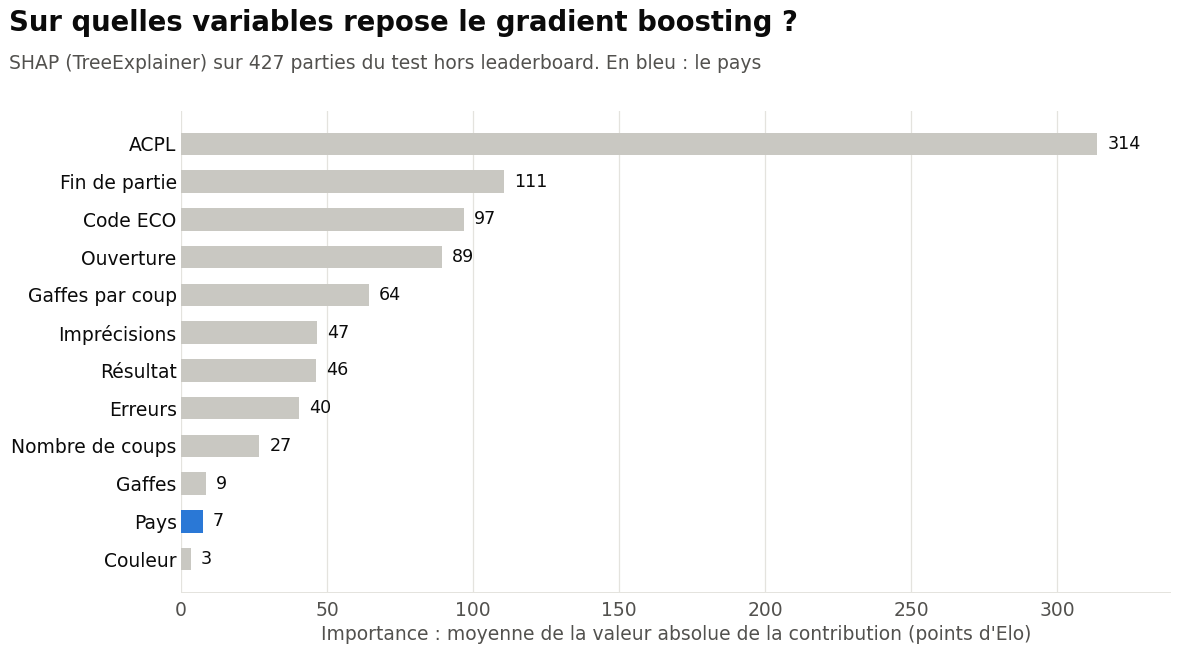

In [5]:
ordered = importance.sort_values()
fig, ax = plt.subplots()
ax.barh([LABELS[variable] for variable in ordered.index], ordered, height=0.6, color=[ACCENT if variable == "country" else MUTED for variable in ordered.index])
for position, value in enumerate(ordered):
    ax.annotate(f"{value:.0f}" if value >= 1 else f"{value:.1f}".replace(".", ","), (value, position), xytext=(8, 0), textcoords="offset points", ha="left", va="center", fontsize=14)
ax.margins(x=0.08)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Importance : moyenne de la valeur absolue de la contribution (points d'Elo)")
fig.text(0.015, 0.95, "Sur quelles variables repose le gradient boosting ?", fontsize=22, fontweight="bold", va="center")
fig.text(0.015, 0.89, f"SHAP (TreeExplainer) sur {len(explained)} parties du test hors leaderboard. En bleu : le pays", fontsize=15, color=INK_2, va="center")
fig.tight_layout(rect=(0, 0, 1, 0.85))
fig.savefig(OUTPUT_DIR / "fig_importance_globale.png")
plt.show()

## 4. Graphique en essaim

Chaque point est une partie. À droite de l'axe, la variable fait monter l'Elo prédit ; à gauche, elle le fait baisser. La couleur donne la valeur de la variable pour les variables numériques. Les variables catégorielles n'ont pas d'ordre : leurs points sont en gris.

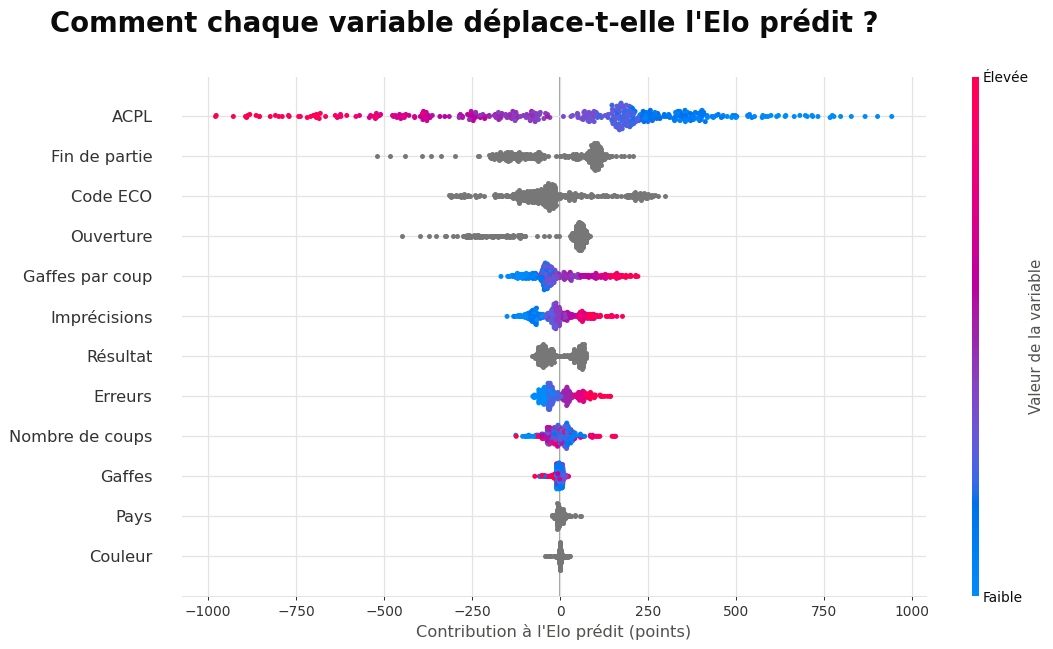

In [6]:
numeric_data = np.column_stack([explained[variable].to_numpy(dtype=float) if variable in NUMERIC else np.full(len(explained), np.nan) for variable in VARIABLES])
swarm = shap.Explanation(values=by_variable[VARIABLES].to_numpy(), base_values=np.ravel(explanation.base_values), data=numeric_data, feature_names=[LABELS[variable] for variable in VARIABLES])
shap.plots.beeswarm(swarm, max_display=len(VARIABLES), show=False, plot_size=(13.33, 7.5), color_bar_label="Valeur de la variable")
figure = plt.gcf()
figure.axes[-1].set_yticklabels(["Faible", "Élevée"])
figure.suptitle("Comment chaque variable déplace-t-elle l'Elo prédit ?", x=0.015, ha="left", fontsize=22, fontweight="bold")
plt.gca().set_xlabel("Contribution à l'Elo prédit (points)")
figure.savefig(OUTPUT_DIR / "fig_essaim.png", bbox_inches="tight")
plt.show()

## 5. Le pays pousse-t-il dans un sens ?

Contribution moyenne du pays, signée, pour les parties de chaque pays. Elle mesure ce que le modèle ajoute ou retire en moyenne à cause de cette seule modalité. L'importance de la section 3 ne le dit pas : elle ignore le signe.

In [7]:
effects = pd.DataFrame({"country": explained["country"].to_numpy(), "shap": by_variable["country"].to_numpy()})
by_country = effects.groupby("country")["shap"].agg(Parties="size", Moyenne="mean", Minimum="min", Maximum="max").reindex(COUNTRY_ORDER).rename(index=COUNTRY_NAMES).rename_axis("Pays")
display(by_country.round(1))
by_country.reset_index().to_csv(OUTPUT_DIR / "contribution_par_pays.csv", index=False)

,Parties,Moyenne,Minimum,Maximum
Pays,,,,
Brésil,65,4.1,-11.5,17.9
Allemagne,65,-8.4,-23.5,5.2
France,166,-5.0,-19.5,4.9
Inde,70,10.3,-1.4,59.0
États-Unis,61,10.0,-3.6,27.3


## Conclusions

**1. Le pays ne pèse presque rien dans ce modèle.** Il représente 0,9 % de l'importance totale (IC 95 % de 0,8 à 1,0), soit 7,5 points d'Elo en moyenne, au rang 11 sur 12. Le train est équilibré par quotas : le pays n'y apporte presque aucune information sur l'Elo, et un modèle qui colle aux données n'a donc rien à en tirer. Ce résultat ne dit rien de ce que ferait le même modèle sur un jeu déséquilibré.

**2. Ce peu n'est pas nul, et son sens varie selon le pays.** La contribution moyenne va de -8,4 points pour l'Allemagne à +10,3 pour l'Inde et +10,0 pour les États-Unis, avec un maximum de +59 sur une partie indienne. Ces écarts sont faibles devant une MAE de 369 points. Rien ici ne permet de dire s'ils tiennent au hasard de l'échantillon de train.

**3. Le modèle repose d'abord sur l'ACPL.** Il compte pour 36,7 % de l'importance : plus l'ACPL est élevé, plus l'Elo prédit baisse, avec des contributions de -979 à +943 points. Viennent ensuite la fin de partie (13,0 %), le code ECO (11,3 %) et l'ouverture (10,5 %).

**4. Trois limites de lecture.**
- **Variables liées.** Le code ECO et le nom de l'ouverture décrivent presque la même chose : leurs parts se partagent le même signal, et leur somme (21,8 %) en donne une meilleure idée que chacune seule. C'est pareil pour l'ACPL, les gaffes et les erreurs.
- **Sens contre-intuitif.** Sur le graphique en essaim, plus d'erreurs, d'imprécisions et de gaffes par coup font monter l'Elo prédit. La contribution d'une variable se lit en présence des autres : c'est peut-être un effet de leur lien avec l'ACPL, mais ce notebook ne le vérifie pas. Elle décrit le modèle, pas l'effet réel d'une erreur sur le niveau d'un joueur.
- **Comparaison avec `06_xai.ipynb`.** Elle reste indicative. Les variables ne sont pas les mêmes (le LLM voit les premiers coups, le gradient boosting voit le code ECO comme variable distincte) et les méthodes non plus : valeurs exactes sur 427 parties ici, estimation par masquage sur 12 parties là-bas.